In [5]:
import pandas as pd
df=pd.read_csv('height-weight.csv')
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df.shape

(23, 2)

In [7]:
df.columns

Index(['Weight', 'Height'], dtype='str')

In [8]:
df.dtypes

Weight    int64
Height    int64
dtype: object

In [9]:
df.info

<bound method DataFrame.info of     Weight  Height
0       45     120
1       58     135
2       48     123
3       60     145
4       70     160
5       78     162
6       80     163
7       90     175
8       95     182
9       78     170
10      82     176
11      95     182
12     105     175
13     100     183
14      85     170
15      78     177
16      50     140
17      65     159
18      76     150
19      87     167
20      45     129
21      56     140
22      72     160>

In [12]:
df.describe()

,Weight,Height
count,23.000000,23.000000
mean,73.826087,158.391304
std,17.872407,19.511626
min,45.000000,120.000000
25%,59.000000,142.500000
50%,78.000000,162.000000
75%,86.000000,175.000000
max,105.000000,183.000000


In [14]:
df.isnull().sum()

Weight    0
Height    0
dtype: int64

#cheching for duplicate rows

In [15]:
df.duplicated().sum()

np.int64(1)

# output showing 1 duplicate row so, get that duplcate row

In [16]:
df[df.duplicated()]

,Weight,Height
11,95,182


# if we want to see both duplicate rows

In [17]:
df[df.duplicated(keep=False)]

,Weight,Height
8,95,182
11,95,182


 finding relationship by using scatter plot

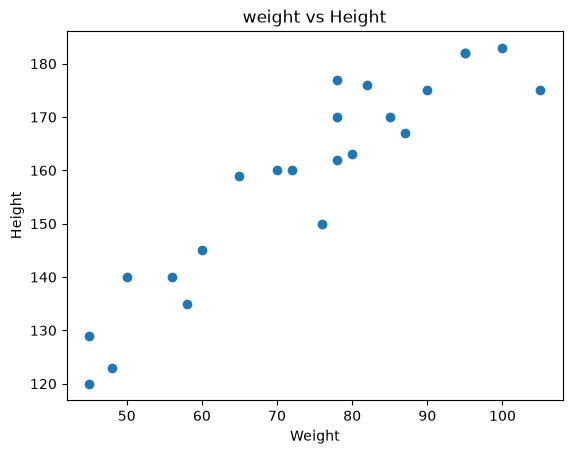

In [21]:
plt.scatter
plt.scatter (df["Weight"],df['Height'])
plt.xlabel('Weight')
plt.ylabel('Height')
plt.title('weight vs Height')
plt.show()


# finding corelation

In [9]:
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


if we want to find out how they are corelated

In [10]:
df["Weight"].corr(df["Height"])

np.float64(0.9311418034329901)

define x and y

In [13]:
x = df[['Weight']]
y = df['Height']

y.shape

(23,)

here x uses [[]] and y use [ ] because x is df and y is series

In [25]:
x.shape

(23, 1)

# Train Test split

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [24]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(18, 1)
(5, 1)
(18,)
(5,)


#create linear regression model

In [15]:
from sklearn.linear_model import LinearRegression

In [16]:
model=LinearRegression()

# Train the model

In [17]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.96]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Weight']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,85.97
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [18]:
model.coef_

array([0.9630459])

In [19]:
slope=model.coef_[0]
print(slope)

0.9630459016070003


In [20]:
model.intercept_

np.float64(85.96709053063559)

# we will make predictions now

In [29]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

In [48]:
print("Actual",y_test.values)
print("Predicetd",y_pred)

Actual [177 170 120 182 159]
Predicetd [161.08467086 161.08467086 129.3041561  177.45645118 148.56507414]


In [49]:
print("Actual",y_test)
print("Predicetd",y_pred)

Actual 15    177
9     170
0     120
8     182
17    159
Name: Height, dtype: int64
Predicetd [161.08467086 161.08467086 129.3041561  177.45645118 148.56507414]


#compare actual vs predicted

In [50]:
comparison = pd.DataFrame({
    "Actual Height": y_test.values,
    "Predicted Height": y_pred
})

comparison

,Actual Height,Predicted Height
0,177,161.084671
1,170,161.084671
2,120,129.304156
3,182,177.456451
4,159,148.565074


#Evaluate the model

In [32]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

#MAE

In [ ]:
#mae of training data
mae_test=mean_absolute_error(y_train,y_train_pred)
print(mae_test)
# mae of testing data   
mae=mean_absolute_error(y_test,y_test_pred)
print(mae)

4.481059846260255
9.822657814519232


In [35]:
#mse of training data
mse_train=mean_squared_error(y_train,y_train_pred)
print('mse of tarin data',mse_train)
# mse of test data
mse=mean_squared_error(y_test,y_test_pred)
print('mse of test data',mse)

mse of tarin data 34.745586257468595
mse of test data 109.77592599051658


#RMSE

In [56]:
rmse=np.sqrt(mse)
print(rmse)

10.477400726827078


In [38]:
#r2 of train
r2_train =r2_score(y_train,y_train_pred)
print('r2 of train',r2_train)

# r2 of test data
r2 = r2_score(y_test, y_test_pred)

print("r²of test:", r2)

r2 of train 0.8930630841011482
r²of test: 0.776986986042344


roughly means the model explains about 80% of the variance in the target on that evaluation set.

Don't interpret R² as "80% prediction accuracy."

#plot the regression Line

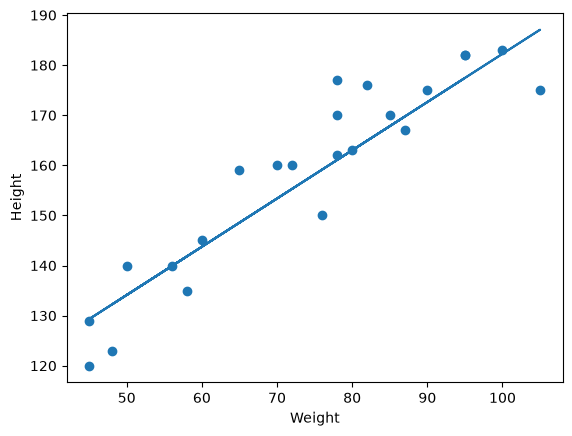

In [ ]:
plt.scatter(x,y)
plt.plot(x,model.predict(x)) ##????
plt.xlabel('Weight')
plt.ylabel("Height")
plt.show()

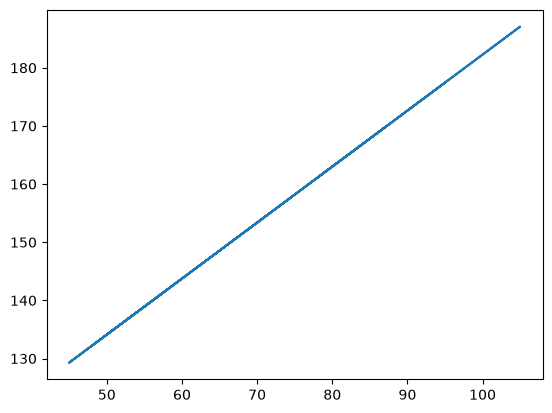

In [64]:
#plt.scatter(x,y)
plt.plot(x,model.predict(x))

# finding residuals

In [62]:
r=y_test - y_pred
print(r)

15    15.915329
9      8.915329
0     -9.304156
8      4.543549
17    10.434926
Name: Height, dtype: float64


In [ ]:
# predicting new person

In [ ]:
new_person = pd.DataFrame({
    "Weight": [75]
})

predicted_height = model.predict(new_person)

print("Predicted Height:", predicted_height[0])

Predicted Height: 158.19553315116062


In [2]:
from sklearn.metrics import r2_score

train_r2 = r2_score(y_train, y_pred)
test_r2 = r2_score(y_test, y_pred)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

NameError: name 'y_train' is not defined